# 05 · Redes recurrentes y pronóstico de series temporales

Las imágenes tienen una estructura espacial; muchas otras señales tienen una **temporal**: la demanda eléctrica, las lecturas de sensores, los precios, la voz, el texto. El orden importa, la longitud varía y lo que pasa ahora depende de lo que pasó antes.

Una **red neuronal recurrente** lee una secuencia paso a paso y lleva consigo una memoria. En este notebook vas a:

| Sección | Idea | Experimento |
|---|---|---|
| 1-3 | el bucle recurrente, las compuertas de la LSTM | escribir a mano una celda RNN |
| 4-5 | pronóstico con variables de calendario | una RNN y una LSTM pronostican 20 días no vistos de demanda horaria, frente a una referencia estacional ingenua |
| 6 | ¿hasta dónde puede recordar una red? | medir lo rápido que se desvanecen los gradientes en el tiempo, y qué cambia la compuerta de olvido de la LSTM |
| 7 | pronóstico directo de varios horizontes | predecir las próximas 24 horas de una vez en lugar de realimentar las predicciones |

Todo se ejecuta en una CPU en pocos minutos, con un conjunto de datos sintético generado en el propio notebook.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import time, random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0); np.random.seed(0); random.seed(0)
torch.set_num_threads(max(1, torch.get_num_threads()))
plt.rcParams["axes.grid"] = False
def count_params(m): return sum(p.numel() for p in m.parameters())

## 1. La idea: un bucle con memoria

Una RNN lee una secuencia paso a paso y mantiene un **estado oculto** $h_t$, un resumen de todo lo visto hasta el momento:

$$ h_t = \tanh(W_{xh} x_t + W_{hh} h_{t-1} + b_h), \qquad \hat y_t = W_{hy} h_t + b_y $$

Se usan los **mismos pesos** en cada paso (igual que una CNN comparte pesos en el espacio, una RNN los comparte en el tiempo). Desplegada en el tiempo, es simplemente una red muy profunda:

```
        y1          y2          y3                yT
        ▲           ▲           ▲                 ▲
h0 ──► [celda] ─h1─► [celda] ─h2─► [celda] ─h3─ ... ─► [celda] ──► hT
        ▲           ▲           ▲                 ▲
        x1          x2          x3                xT
```

El entrenamiento usa **retropropagación a través del tiempo (BPTT)**: retropropagación normal sobre el grafo desplegado. Como el gradiente se multiplica por $W_{hh}$ y por $\tanh'$ en cada paso, **se desvanece** (o explota) en secuencias largas, así que una RNN simple olvida lo que pasó hace más de unas pocas decenas de pasos.

## 2. La solución de la LSTM: memoria con compuertas

La celda **Long Short-Term Memory** (memoria a corto y largo plazo; Hochreiter y Schmidhuber, 1997) añade un **estado de celda** $c_t$ aparte, que fluye en el tiempo sobre todo mediante *sumas*, controlado por tres **compuertas** sigmoides:

| Compuerta | Fórmula | Significado |
|---|---|---|
| olvido $f_t$ | $\sigma(W_f[h_{t-1},x_t]+b_f)$ | qué borrar de la memoria |
| entrada $i_t$ | $\sigma(W_i[h_{t-1},x_t]+b_i)$ | cuánta información nueva escribir |
| candidata $\tilde c_t$ | $\tanh(W_c[h_{t-1},x_t]+b_c)$ | la información nueva |
| salida $o_t$ | $\sigma(W_o[h_{t-1},x_t]+b_o)$ | qué mostrar como $h_t$ |

$$ c_t = f_t \odot c_{t-1} + i_t \odot \tilde c_t, \qquad h_t = o_t \odot \tanh(c_t) $$

Cuando $f_t \approx 1$, el gradiente fluye a lo largo de $c_t$ casi intacto: la misma idea de "autopista aditiva" que las conexiones residuales de ResNet y el flujo residual del transformer. La **GRU** es una variante más ligera con dos compuertas.

## 3. Una celda RNN escrita a mano

In [2]:
class ManualRNN(nn.Module):
    def __init__(self, n_in, n_hidden):
        super().__init__()
        self.Wxh = nn.Linear(n_in, n_hidden)
        self.Whh = nn.Linear(n_hidden, n_hidden, bias=False)
        self.n_hidden = n_hidden
    def forward(self, x):                       # x: (lote, tiempo, variables)
        h = torch.zeros(x.shape[0], self.n_hidden)
        states = []
        for t in range(x.shape[1]):             # la recurrencia: los mismos pesos en cada paso
            h = torch.tanh(self.Wxh(x[:, t]) + self.Whh(h))
            states.append(h)
        return torch.stack(states, dim=1)

rnn = ManualRNN(1, 4)
print("forma de los estados ocultos:", tuple(rnn(torch.randn(2, 10, 1)).shape), "= (lote, tiempo, oculto)")

forma de los estados ocultos: (2, 10, 4) = (lote, tiempo, oculto)


## 4. Datos: una señal sintética de "demanda" horaria

Muchas series reales (carga eléctrica, tráfico web, ventas) se parecen a esta: un ciclo **diario**, un ciclo **semanal** (fines de semana más bajos), una **tendencia** lenta y **ruido**. Generamos 120 días de datos horarios, entrenamos con los primeros 100 días y pronosticamos el resto.

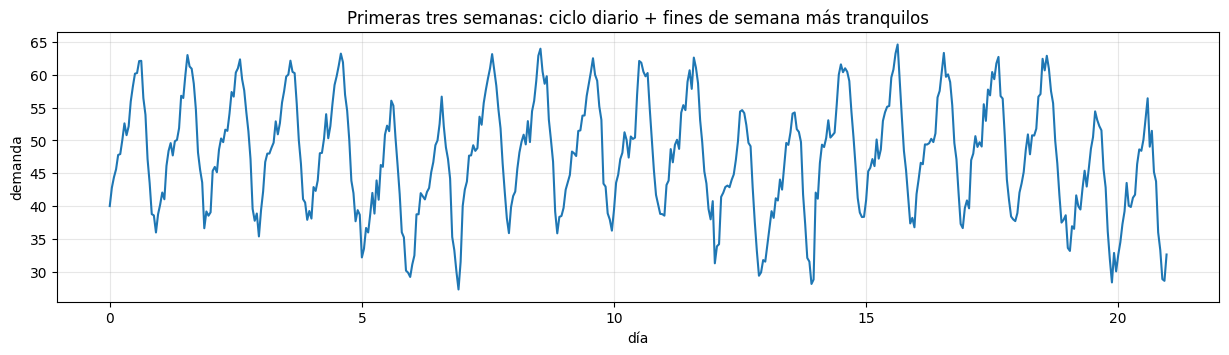

In [3]:
rng = np.random.default_rng(7)
hours = np.arange(24 * 120)
daily = 10 * np.sin(2 * np.pi * (hours % 24 - 6) / 24) + 4 * np.sin(4 * np.pi * (hours % 24) / 24)
weekend = np.where((hours // 24) % 7 >= 5, -8.0, 0.0)
trend = 0.01 * hours / 24
noise_sd = 1.5
series = 50 + daily + weekend + trend + rng.normal(0, noise_sd, len(hours))

split = 24 * 100
mu, sd = series[:split].mean(), series[:split].std()
s_norm = (series - mu) / sd                       # normaliza siempre las entradas de una red neuronal

plt.figure(figsize=(15, 3.5))
plt.plot(hours[:24 * 21] / 24, series[:24 * 21])
plt.xlabel("día"); plt.ylabel("demanda"); plt.title("Primeras tres semanas: ciclo diario + fines de semana más tranquilos"); plt.grid(alpha=0.3); plt.show()

Convertimos la serie en ejemplos supervisados con una **ventana deslizante**: el modelo ve las últimas `W = 48` horas y predice la siguiente.

Cada paso de tiempo lleva 5 variables: la demanda (normalizada) más cuatro **variables de calendario**, el $\sin/\cos$ de la hora del día y de la hora de la semana. Las variables de calendario se conocen de antemano, así que también están disponibles al pronosticar el futuro, y le dicen a la red *en qué punto de la semana está* sin tener que recordar una semana entera de historia. Es la práctica habitual en el pronóstico real de demanda.

In [4]:
W = 48
calendar = np.stack([np.sin(2 * np.pi * hours / 24), np.cos(2 * np.pi * hours / 24),
                     np.sin(2 * np.pi * hours / 168), np.cos(2 * np.pi * hours / 168)], axis=1)

def make_input(values, t):
    # values: los W valores de demanda anteriores a la hora t; calendario desplazado uno para que cada paso también "conozca" la hora siguiente
    return np.concatenate([np.asarray(values)[:, None], calendar[t - W + 1:t + 1]], axis=1)

def windows(s, start, end):
    X = [make_input(s[t - W:t], t) for t in range(start + W, end)]
    Y = [s[t] for t in range(start + W, end)]
    return torch.tensor(np.array(X), dtype=torch.float32), torch.tensor(np.array(Y), dtype=torch.float32)

Xs_tr, ys_tr = windows(s_norm, 0, split)
print("ventanas de entrenamiento:", tuple(Xs_tr.shape), "= (muestras, pasos de tiempo, variables) -> objetivos", tuple(ys_tr.shape))

class Forecaster(nn.Module):
    def __init__(self, kind="lstm", hidden=32):
        super().__init__()
        cls = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[kind]
        self.rnn = cls(input_size=5, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1]).squeeze(-1)    # se usa el último estado oculto

def fit_forecaster(model, epochs=10, lr=3e-3, batch=64):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for ep in range(epochs):
        perm = torch.randperm(len(Xs_tr))
        for i in range(0, len(Xs_tr), batch):
            b = perm[i:i + batch]
            loss = F.mse_loss(model(Xs_tr[b]), ys_tr[b])
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)      # protección estándar contra la explosión de gradientes
            opt.step(); losses.append(loss.item())
    return losses

models = {}
for kind in ["rnn", "lstm"]:
    torch.manual_seed(0)
    t0 = time.time()
    models[kind] = Forecaster(kind)
    l = fit_forecaster(models[kind])
    print(f"{kind.upper():4s} parámetros {count_params(models[kind]):5d}  MSE final de entrenamiento {np.mean(l[-50:]):.4f}  ({time.time() - t0:.0f} s)")

ventanas de entrenamiento: (2352, 48, 5) = (muestras, pasos de tiempo, variables) -> objetivos (2352,)


RNN  parámetros  1281  MSE final de entrenamiento 0.0454  (6 s)


LSTM parámetros  5025  MSE final de entrenamiento 0.0394  (3 s)


## 5. Pronosticar los 20 días no vistos

Hay dos formas de usar el modelo:
* **Un paso por delante:** en cada hora se le dan las 48 horas anteriores *reales* y predice la siguiente.
* **Varios pasos de forma recursiva:** predice la hora 1, se añade la predicción a la entrada, predice la hora 2, y así durante toda una semana. Los errores se acumulan, así que es mucho más difícil y más parecido al pronóstico real.

Comparamos con la referencia **estacional ingenua** ("la misma hora de la semana pasada"), una referencia sorprendentemente fuerte que cualquier modelo de pronóstico debe superar. El ruido que añadimos tiene una desviación típica de 1,5, así que un RMSE de 1,5 es lo mejor que podría lograr cualquier modelo.

modelo    RMSE 1 paso  RMSE recursivo 7 días
(suelo)          1.50                   1.50
ingenuo          2.12                   2.15


RNN              1.89                   2.44
LSTM             1.80                   2.07


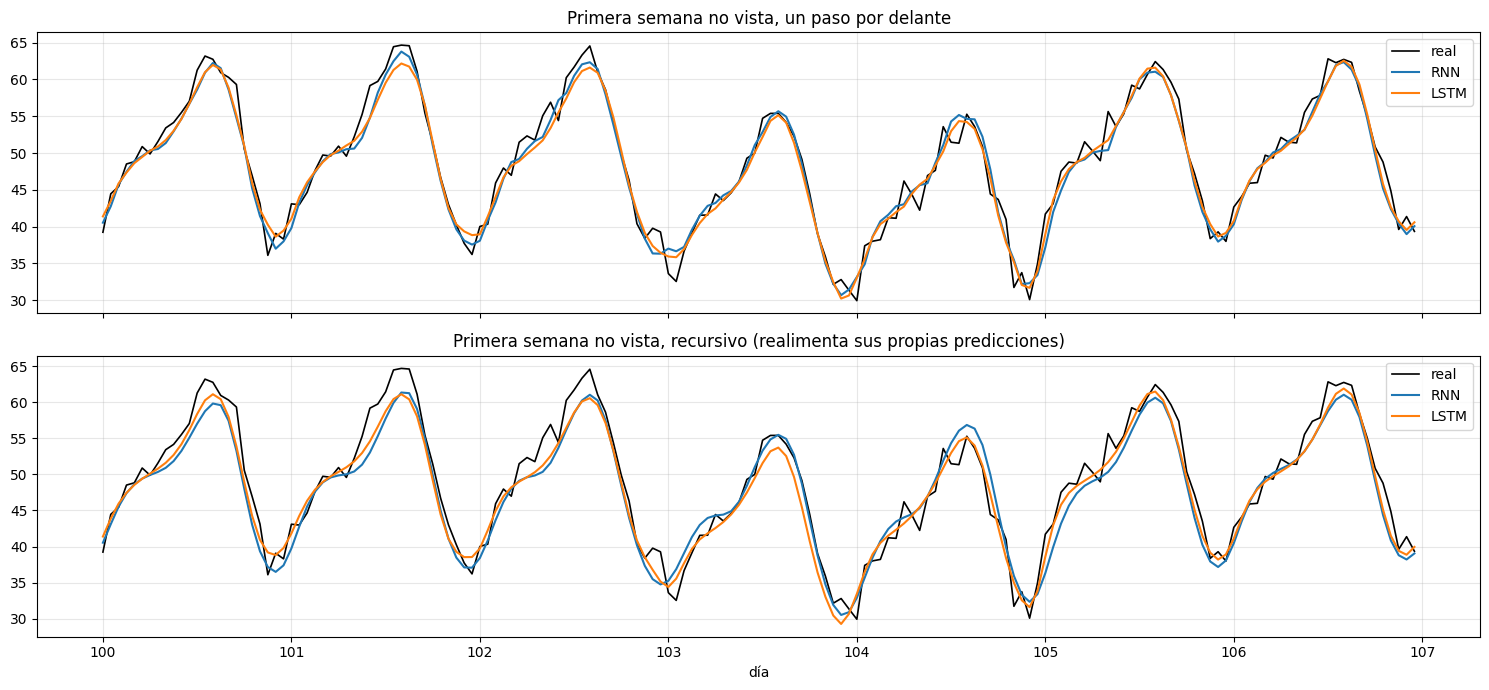

In [5]:
def one_step(model):
    Xv, _ = windows(s_norm, split - W, len(s_norm))     # una ventana por cada hora no vista
    with torch.no_grad():
        return model(Xv).numpy() * sd + mu

def recursive(model, horizon):
    hist = list(s_norm[split - W:split])
    preds = []
    with torch.no_grad():
        for k in range(horizon):
            x = torch.tensor(make_input(hist[-W:], split + k), dtype=torch.float32).unsqueeze(0)
            p = model(x).item()
            preds.append(p); hist.append(p)               # la predicción se convierte en la siguiente entrada
    return np.array(preds) * sd + mu

truth = series[split:]
naive = series[split - 168:len(series) - 168]
rmse = lambda a, b: np.sqrt(np.mean((a - b) ** 2))

print(f"{'modelo':8s} {'RMSE 1 paso':>12s} {'RMSE recursivo 7 días':>22s}")
print(f"{'(suelo)':8s} {noise_sd:12.2f} {noise_sd:22.2f}")
print(f"{'ingenuo':8s} {rmse(naive, truth):12.2f} {rmse(naive[:168], truth[:168]):22.2f}")
forecasts = {}
for kind, m in models.items():
    os_pred = one_step(m)
    rec = recursive(m, 168)
    forecasts[kind] = (os_pred, rec)
    print(f"{kind.upper():8s} {rmse(os_pred, truth):12.2f} {rmse(rec, truth[:168]):22.2f}")

fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)
t = hours[split:split + 168] / 24
for ax, (label, idx) in zip(axes, [("un paso por delante", 0), ("recursivo (realimenta sus propias predicciones)", 1)]):
    ax.plot(t, truth[:168], color="k", lw=1.2, label="real")
    for kind in models:
        ax.plot(t, forecasts[kind][idx][:168], lw=1.5, label=kind.upper())
    ax.set_title(f"Primera semana no vista, {label}"); ax.legend(loc="upper right"); ax.grid(alpha=0.3)
axes[1].set_xlabel("día"); plt.tight_layout(); plt.show()

Cosas en las que fijarse:
* Ambas redes aprenden de los datos las formas diaria y semanal, y superan a la referencia estacional ingenua un paso por delante.
* En modo recursivo, la LSTM suele ser la más estable de las dos: su estado de celda con compuertas lleva la información a lo largo de muchos pasos, justo donde los gradientes de la RNN simple se desvanecen.
* Los pronósticos recursivos empeoran a medida que se acumulan los errores. La sección 7 elimina ese bucle de realimentación.

## 6. ¿Hasta dónde puede recordar una red recurrente?

La sección 1 afirmaba que los gradientes se desvanecen en el tiempo. Podemos medirlo directamente. Damos a una red una secuencia aleatoria de 100 pasos y calculamos cuánto depende el estado oculto **final** de cada entrada:

$$ \text{sensibilidad}(t) = \left\| \frac{\partial h_T}{\partial x_t} \right\| $$

Si decae rápido a medida que $t$ se aleja de $T$, la red no puede aprender dependencias de largo alcance: la señal de entrenamiento de la pérdida nunca llega a esos primeros pasos.

Comparamos una RNN simple con varias LSTM que solo se diferencian **en el sesgo inicial de la compuerta de olvido**. Con sesgo 0, la compuerta de olvido empieza en $\sigma(0) = 0.5$, así que el estado de celda se reduce a la mitad en cada paso, de forma muy parecida a la multiplicación repetida de la RNN. Un sesgo positivo hace que la compuerta empiece cerca de 1 ("recordar por defecto"), un truco recomendado por Gers et al. (2000) y Jozefowicz et al. (2015). El equivalente en la GRU es su compuerta de *actualización*.

RNN                                              sensibilidad 50 pasos atrás: 7.6e-12
LSTM, sesgo de olvido 0 (por defecto en PyTorch) sensibilidad 50 pasos atrás: 8.2e-12
LSTM, sesgo de olvido 1                          sensibilidad 50 pasos atrás: 2.0e-05
LSTM, sesgo de olvido 3                          sensibilidad 50 pasos atrás: 2.0e-02


GRU, sesgo de actualización 3                    sensibilidad 50 pasos atrás: 2.9e-03


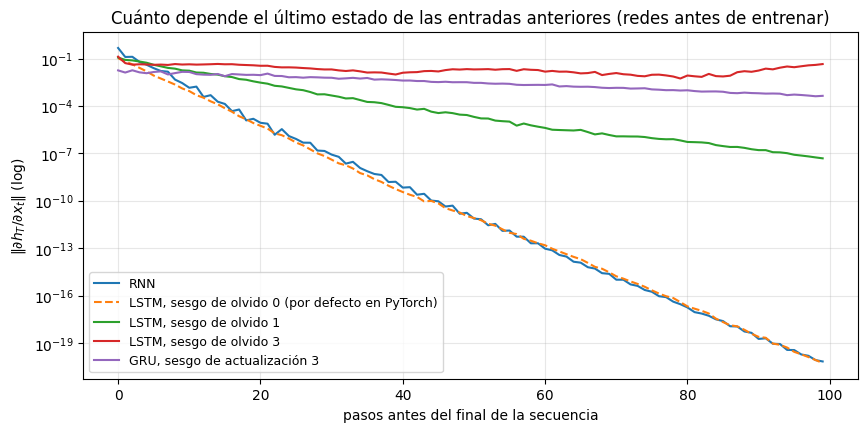

In [6]:
def gated(cls, gate_bias):
    net = cls(input_size=1, hidden_size=32, batch_first=True)
    with torch.no_grad():
        # PyTorch apila los parámetros de las compuertas; las filas 32:64 son la compuerta de olvido de la LSTM y la de actualización de la GRU
        net.bias_ih_l0[32:64].fill_(gate_bias / 2); net.bias_hh_l0[32:64].fill_(gate_bias / 2)
    return net

variants = {
    "RNN": lambda: nn.RNN(input_size=1, hidden_size=32, batch_first=True),
    "LSTM, sesgo de olvido 0 (por defecto en PyTorch)": lambda: gated(nn.LSTM, 0.0),
    "LSTM, sesgo de olvido 1": lambda: gated(nn.LSTM, 1.0),
    "LSTM, sesgo de olvido 3": lambda: gated(nn.LSTM, 3.0),
    "GRU, sesgo de actualización 3": lambda: gated(nn.GRU, 3.0),
}
T = 100
fig, ax = plt.subplots(figsize=(10, 4.5))
for name, make in variants.items():
    sens = []
    for seed in range(5):
        torch.manual_seed(seed)
        net = make()
        x = torch.randn(1, T, 1, requires_grad=True)
        out, _ = net(x)
        out[0, -1].sum().backward()
        sens.append(x.grad[0, :, 0].abs().numpy())
    s = np.mean(sens, 0)[::-1]
    ax.semilogy(np.arange(T), s, label=name, ls="--" if "defecto" in name else "-")
    print(f"{name:48s} sensibilidad 50 pasos atrás: {s[50]:.1e}")
ax.set_xlabel("pasos antes del final de la secuencia"); ax.set_ylabel(r"$\|\partial h_T / \partial x_t\|$ (log)")
ax.set_title("Cuánto depende el último estado de las entradas anteriores (redes antes de entrenar)"); ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.show()

Dos lecciones en una sola gráfica:

* Con la configuración por defecto, la LSTM olvida **tan rápido como la RNN simple**: la dependencia de una entrada de hace 50 pasos es menor que $10^{-10}$ en ambas. Las compuertas hacen *posible* la memoria larga, no la hacen automática.
* Abrir la compuerta de olvido lo cambia todo. Con sesgo 3, el estado de celda se transmite casi sin cambios y la sensibilidad apenas decae en 100 pasos. Durante el entrenamiento, una LSTM puede aprender esos valores de compuerta donde la tarea los necesite, y partir de un sesgo de olvido positivo lo facilita mucho.

Una RNN simple no tiene ese mando: su memoria se multiplica por $W_{hh}$ y se comprime con $\tanh$ en cada paso, y mantener ese producto cerca de 1 durante tramos largos es justo lo que le cuesta al descenso de gradiente. Esta es la razón práctica por la que las LSTM y las GRU sustituyeron a las RNN simples, y la misma idea de "un camino aditivo para el gradiente" reaparece en las ResNet (notebook 04) y en los transformers (notebook 07).

## 7. Pronóstico directo de varios horizontes

Los pronósticos reales suelen necesitarse para todo un horizonte a la vez, por ejemplo **las 24 horas de mañana**, emitidos cada día a medianoche (así funcionan los mercados eléctricos diarios). Hay dos formas de conseguirlo:

* **Recursiva:** el modelo de un paso de la sección 5, ejecutado 24 veces, realimentando cada predicción como entrada.
* **Directa:** un modelo cuya capa de salida tiene 24 unidades, entrenado para predecir las 24 horas a partir de la misma historia de 48 horas. Sin bucle de realimentación, así que sin acumulación de errores, y cada salida puede especializarse en su propio horizonte.

Evaluamos ambos de la forma honesta: un pronóstico por cada día no visto, emitido a medianoche y evaluado sobre las 24 horas siguientes.

modelo directo entrenado en 3 s



RMSE del día siguiente sobre 20 días no vistos (suelo de ruido 1.5)
  estacional ingenuo 2.12
  LSTM recursiva     2.12
  LSTM directa       1.70


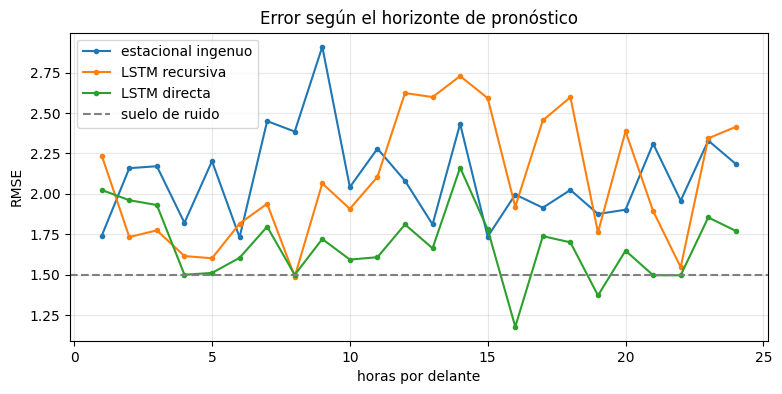

In [7]:
H = 24
def windows_direct(s, start, end, step=1):
    X, Y = [], []
    for t in range(start + W, end - H + 1, step):
        X.append(make_input(s[t - W:t], t)); Y.append(s[t:t + H])
    return torch.tensor(np.array(X), dtype=torch.float32), torch.tensor(np.array(Y), dtype=torch.float32)

class DirectForecaster(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.rnn = nn.LSTM(input_size=5, hidden_size=hidden, batch_first=True)
        self.head = nn.Linear(hidden, H)             # una salida por cada hora futura
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1])

Xd_tr, Yd_tr = windows_direct(s_norm, 0, split)
torch.manual_seed(0)
direct = DirectForecaster()
opt = torch.optim.Adam(direct.parameters(), lr=3e-3)
t0 = time.time()
for ep in range(10):
    perm = torch.randperm(len(Xd_tr))
    for i in range(0, len(Xd_tr), 64):
        b = perm[i:i + 64]
        loss = F.mse_loss(direct(Xd_tr[b]), Yd_tr[b])
        opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(direct.parameters(), 1.0); opt.step()
print(f"modelo directo entrenado en {time.time() - t0:.0f} s")

def recursive_from(model, origin, horizon):
    hist = list(s_norm[origin - W:origin]); preds = []
    with torch.no_grad():
        for k in range(horizon):
            p = model(torch.tensor(make_input(hist[-W:], origin + k), dtype=torch.float32).unsqueeze(0)).item()
            preds.append(p); hist.append(p)
    return np.array(preds) * sd + mu

origins = range(split, len(series) - H + 1, 24)         # cada medianoche no vista
err = {"estacional ingenuo": [], "LSTM recursiva": [], "LSTM directa": []}
for o in origins:
    y = series[o:o + H]
    err["estacional ingenuo"].append(series[o - 168:o - 168 + H] - y)
    err["LSTM recursiva"].append(recursive_from(models["lstm"], o, H) - y)
    with torch.no_grad():
        d = direct(torch.tensor(make_input(s_norm[o - W:o], o), dtype=torch.float32).unsqueeze(0))[0].numpy() * sd + mu
    err["LSTM directa"].append(d - y)

print(f"\nRMSE del día siguiente sobre {len(origins)} días no vistos (suelo de ruido {noise_sd})")
fig, ax = plt.subplots(figsize=(9, 4))
for name, e in err.items():
    e = np.array(e)
    print(f"  {name:18s} {np.sqrt((e ** 2).mean()):.2f}")
    ax.plot(range(1, H + 1), np.sqrt((e ** 2).mean(0)), marker="o", ms=3, label=name)
ax.axhline(noise_sd, color="gray", ls="--", label="suelo de ruido")
ax.set_xlabel("horas por delante"); ax.set_ylabel("RMSE"); ax.set_title("Error según el horizonte de pronóstico"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

La gráfica por horizonte muestra el mecanismo: el error del modelo recursivo crece con cada hora porque cada paso hereda los errores del anterior, mientras que el error del modelo directo se mantiene más o menos plano a lo largo del día. Los sistemas de pronóstico en producción suelen ir un paso más allá y producir una **distribución** completa por hora (cuantiles), para que las decisiones posteriores puedan tener en cuenta la incertidumbre.

## Resumen

| Modelo | Idea clave | Punto fuerte | Punto débil |
|---|---|---|---|
| RNN simple | función de paso compartida + estado oculto | simple, procesa en flujo | la memoria se desvanece en unas pocas decenas de pasos |
| LSTM / GRU | memoria aditiva con compuertas | recuerda mucho más, entrenamiento estable | sigue siendo secuencial, así que lenta de entrenar con secuencias largas |
| directo de varios horizontes | una salida por cada paso futuro | sin acumulación de errores | horizonte fijado de antemano |

Las redes recurrentes siguen siendo una buena opción para problemas pequeños y en flujo. Con secuencias largas y conjuntos de datos grandes, las superó la atención (notebooks 06 y 07), que mira cada paso pasado directamente en lugar de pasar una memoria a lo largo de una cadena.

## Ejercicios

1. Sustituye `"lstm"` por `"gru"` en la sección 5. Después quita las variables de calendario (tamaño de entrada 1) y usa una ventana de 168 horas: ¿qué modelo sufre más y por qué?
2. Construye una prueba de memoria: el primer valor de una secuencia es +1 o −1, el resto son ruido, y la red debe dar el signo después de leerlo todo. Entrena una RNN y una LSTM con longitudes 10, 30 y 100. ¿Cuánto entrenamiento necesita cada una y dónde se rinde cada una?
3. Vuelve a entrenar la LSTM de la sección 5 con el sesgo de la compuerta de olvido inicializado a 1 (reutiliza `gated`). ¿Mejora el pronóstico recursivo de 7 días?
4. Convierte el modelo directo en un pronosticador de **cuantiles**: produce los percentiles 10, 50 y 90 para cada hora usando la pérdida pinball. ¿Con qué frecuencia cae el valor real dentro de la banda 10-90?